<a href="https://colab.research.google.com/github/ialexbaltag/ml-product-prediction/blob/main/notebook/ml_prediction_product.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Loading and inspecting the dataset

- load csv file

- check how many rows and columns are

- display first fwe rows

- review data types and basic metadata for each column

In [17]:
import pandas as pd

# load dataset from GitHub
url = "https://raw.githubusercontent.com/ialexbaltag/ml-product-prediction/main/data/products.csv"
df = pd.read_csv(url)

print("Number of rows:", len(df))
print("First 5 rows:")
print(df.head())

Number of rows: 35311
First 5 rows:
   product ID                                      Product Title  Merchant ID  \
0           1                    apple iphone 8 plus 64gb silver            1   
1           2                apple iphone 8 plus 64 gb spacegrau            2   
2           3  apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...            3   
3           4                apple iphone 8 plus 64gb space grey            4   
4           5  apple iphone 8 plus gold 5.5 64gb 4g unlocked ...            5   

   Category Label _Product Code  Number_of_Views  Merchant Rating  \
0   Mobile Phones    QA-2276-XC            860.0              2.5   
1   Mobile Phones    KA-2501-QO           3772.0              4.8   
2   Mobile Phones    FP-8086-IE           3092.0              3.9   
3   Mobile Phones    YI-0086-US            466.0              3.4   
4   Mobile Phones    NZ-3586-WP           4426.0              1.6   

   Listing Date    
0       5/10/2024  
1      12/31/2024  
2 

In [18]:
# Print shape (number of rows and columns)
print("Dataset shape (rows, columns):", df.shape)

# Show first 5 rows
print("\nFirst 5 rows:")
display(df.head())

# Show column data types and non-null counts
print("\nDataset info:")
df.info()

Dataset shape (rows, columns): (35311, 8)

First 5 rows:


,product ID,Product Title,Merchant ID,Category Label,_Product Code,Number_of_Views,Merchant Rating,Listing Date
0,1,apple iphone 8 plus 64gb silver,1,Mobile Phones,QA-2276-XC,860.0,2.5,5/10/2024
1,2,apple iphone 8 plus 64 gb spacegrau,2,Mobile Phones,KA-2501-QO,3772.0,4.8,12/31/2024
2,3,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...,3,Mobile Phones,FP-8086-IE,3092.0,3.9,11/10/2024
3,4,apple iphone 8 plus 64gb space grey,4,Mobile Phones,YI-0086-US,466.0,3.4,5/2/2022
4,5,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,5,Mobile Phones,NZ-3586-WP,4426.0,1.6,4/12/2023



Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35311 entries, 0 to 35310
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   product ID       35311 non-null  int64  
 1   Product Title    35139 non-null  object 
 2   Merchant ID      35311 non-null  int64  
 3    Category Label  35267 non-null  object 
 4   _Product Code    35216 non-null  object 
 5   Number_of_Views  35297 non-null  float64
 6   Merchant Rating  35141 non-null  float64
 7    Listing Date    35252 non-null  object 
dtypes: float64(2), int64(2), object(4)
memory usage: 2.2+ MB


## Checkingfor missing values
- first standardized the columns titles
- count the number of missing (Nan) values per column
- visualize missing values using a heatmap

In [19]:
# stadardized colmns titles
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace("*", "", regex=False)
    .str.replace(" ", "_", regex=False)
    .str.strip("_")
)

# print(df.columns)

In [20]:
# Count missing values per column
print("Missing values per column:")
print(df.isna().sum())

Missing values per column:
product_id           0
product_title      172
merchant_id          0
category_label      44
product_code        95
number_of_views     14
merchant_rating    170
listing_date        59
dtype: int64


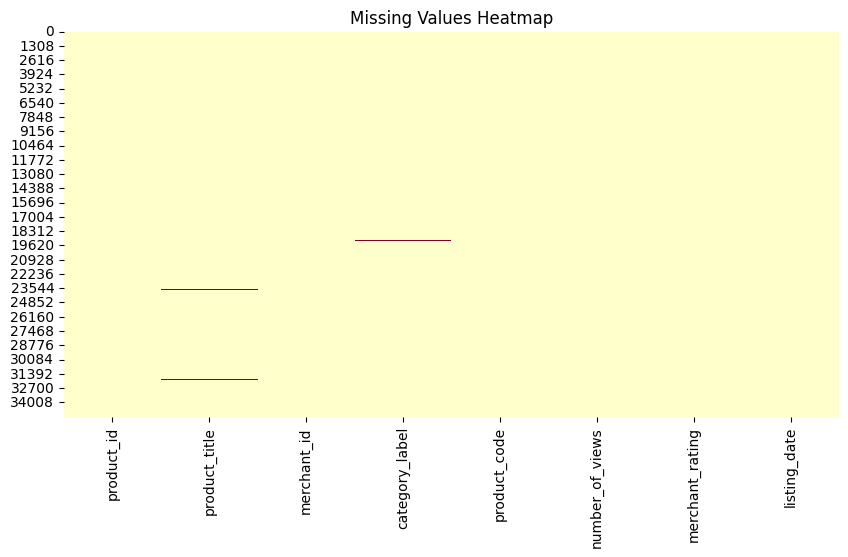

In [21]:
# Visualize missing data with seaborn heatmap
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
sns.heatmap(df.isna(), cbar=False, cmap="YlOrRd")
plt.title("Missing Values Heatmap")
plt.show()

## Implementing EDA (Exploratory Data Analysis)

## Category analysis

- understand the balance between classes
- detect if the dataset is skewed

In [22]:
# Count occurrences of each category label (unique values)
category_label_counts = df['category_label'].value_counts()

# Print counts
print("Category label distribution (counts):")
print(category_label_counts)

Category label distribution (counts):
category_label
Fridge Freezers     5495
Washing Machines    4036
Mobile Phones       4020
CPUs                3771
TVs                 3564
Fridges             3457
Dishwashers         3418
Digital Cameras     2696
Microwaves          2338
Freezers            2210
fridge               123
CPU                   84
Mobile Phone          55
Name: count, dtype: int64


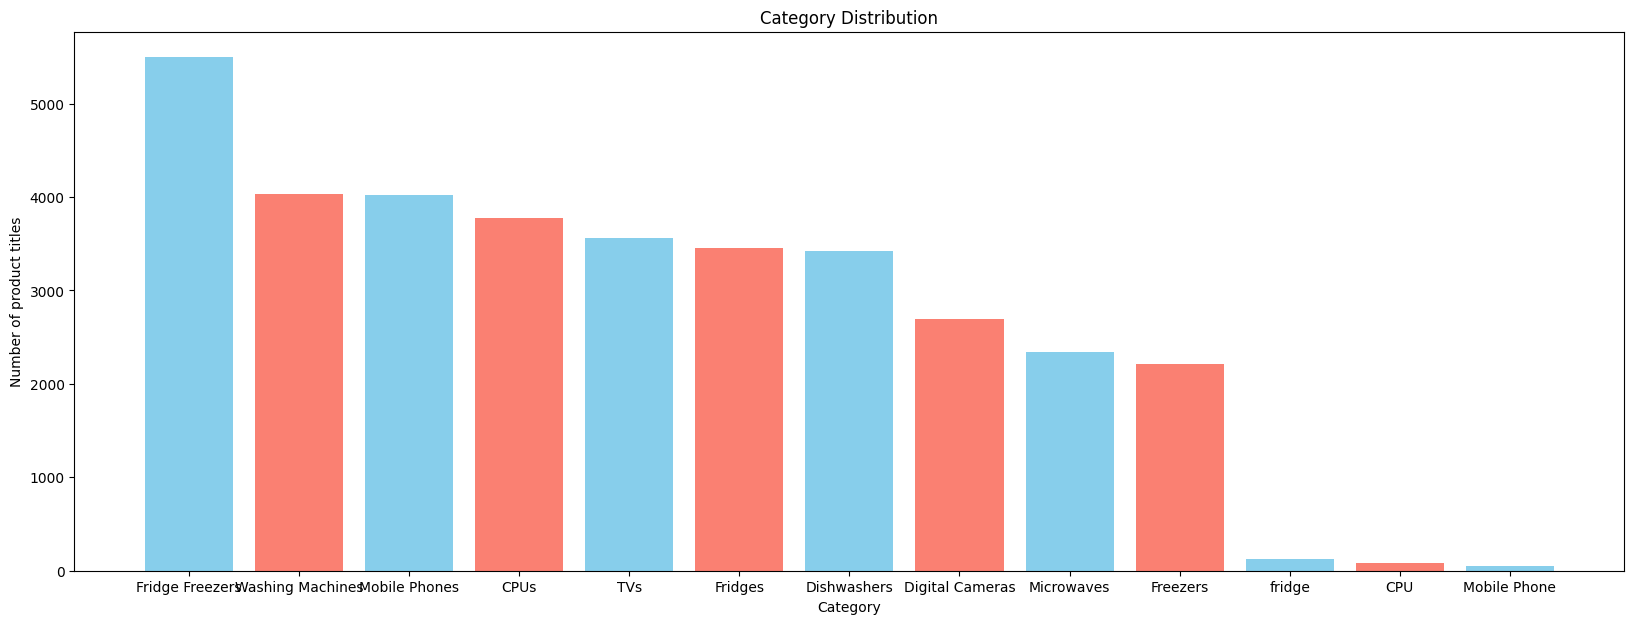

In [23]:
# Plot category distribution
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 7))
plt.bar(category_label_counts.index, category_label_counts.values, color=['skyblue', 'salmon'])
plt.title("Category Distribution")
plt.xlabel("Category")
plt.ylabel("Number of product titles")
plt.show()

## Product title analysis

-check for values and non values texts from column product title


In [24]:
# 1. Check the data type of the 'product_title' column
print("Data type of product_price column:", df['product_title'].dtype)

# 2. Display the first 10 values from the column
print("\nFirst 10 values in product_title column:")
print(df['product_title'].head(10))

# 3. Show the 20 most frequent values in the column
print("\nTop 20 most frequent values in product_title column:")
print(df['product_title'].value_counts().head(20))

# 4. Check for known non text values
problematic_values = ['Free', 'Not Available', 'N/A', 'None', '-', 'free', 'unknown', 'Unavailable', 'NaN']
# Identify rows containing these specific non values
mask_problematic = df['product_title'].astype(str).str.strip().isin(problematic_values)
df_problematic = df[mask_problematic]
print(f"\nFound {len(df_problematic)} rows with problematic textual values:")
display(df_problematic[['product_title']].drop_duplicates())

# 5. Find and display some of the non-text values in column category label
invalid_category_label = df[df["category_label"].apply(lambda x: not isinstance(x, str))]

print("Number of non-text in category labels:",len(invalid_category_label))

print(invalid_category_label[["category_label"]].drop_duplicates().head(20))


Data type of product_price column: object

First 10 values in product_title column:
0                      apple iphone 8 plus 64gb silver
1                  apple iphone 8 plus 64 gb spacegrau
2    apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...
3                  apple iphone 8 plus 64gb space grey
4    apple iphone 8 plus gold 5.5 64gb 4g unlocked ...
5    apple iphone 8 plus gold 5.5 64gb 4g unlocked ...
6                 apple iphone 8 plus 64 gb space grey
7                  apple iphone 8 plus 64gb space grey
8                  apple iphone 8 plus 64gb space grey
9                  apple iphone 8 plus 64gb space grey
Name: product_title, dtype: object

Top 20 most frequent values in product_title column:
product_title
washing machine                                                           90
built in fully integrated dishwasher                                      35
frost free fridge freezer                                                 34
washer dryer                    

,product_title


Number of non-text in category labels: 44
    category_label
162            NaN


## Removing missing values
- drop all rows with missing values
- check the new shape and count the missing values per column

In [25]:
# Drop all rows with missing values
df = df.dropna()

# Display new shape of the dataset
print("New dataset shape:", df.shape)

# Count missing values per column
print("Missing values per column:")
print(df.isna().sum())

New dataset shape: (34760, 8)
Missing values per column:
product_id         0
product_title      0
merchant_id        0
category_label     0
product_code       0
number_of_views    0
merchant_rating    0
listing_date       0
dtype: int64


## Insuring the columns category_label and product_title are texts

In [26]:
df["category_label_cleaned"] = (df["category_label"].astype(str).str.strip())

df = df.drop(columns=['category_label_cleaned'])

# Drop any rows where conversion failed (still NaN)
df = df.dropna(subset=['category_label'])

# Confirm result
print("Column type after parsing:", df['category_label'].dtype)
print("\nCategory label summary:")
print(df['category_label'].describe())


# Same operation for column product_title
df["product_title_cleaned"] = (df["product_title"].astype(str).str.strip())

df = df.drop(columns=['product_title_cleaned'])

# Drop any rows where conversion failed (still NaN)
df = df.dropna(subset=['product_title'])

# Confirm result
print("Column type after parsing:", df['product_title'].dtype)
print("\nProduct title summary:")
print(df['product_title'].describe())



Column type after parsing: object

Category label summary:
count               34760
unique                 13
top       Fridge Freezers
freq                 5424
Name: category_label, dtype: object
Column type after parsing: object

Product title summary:
count               34760
unique              30552
top       washing machine
freq                   89
Name: product_title, dtype: object


## Standardizing the category_label column

- convert all values to lowercase,
- check results

In [27]:
# Convert all category label values to lowercase and strip extra spaces
df['category_label'] = df['category_label'].astype(str).str.lower().str.strip()

# Show all unique values in the sentiment column
print("Unique category label values after cleaning:")
print(df['category_label'].value_counts())

# Convert column type to 'category'
df['category_label'] = df['category_label'].astype('category')
print("\nCategory label column converted to type:", df['category_label'].dtype)


Unique category label values after cleaning:
category_label
fridge freezers     5424
washing machines    3971
mobile phones       3970
cpus                3711
tvs                 3502
fridges             3403
dishwashers         3374
digital cameras     2661
microwaves          2307
freezers            2182
fridge               121
cpu                   81
mobile phone          53
Name: count, dtype: int64

Category label column converted to type: category


## Feature Engineering

## Removing irrelevant columns and keeping the rest

- columns unused for training: product_id, merchant_id,
number_of_views, merchant_rating, listing_date;

- columns to keep: category_label (target variable), product_title (short text) and product_code (series of the product)

In [28]:
# Drop columns that are not useful for modeling
df = df.drop(columns=['product_id', 'merchant_id','number_of_views', 'merchant_rating','listing_date'])

# Preview remaining columns
print("Remaining columns:")
print(df.columns.tolist())

Remaining columns:
['product_title', 'category_label', 'product_code']


## Creating a new feature : 'product_title_length'
- represents the number of characters in each product title
and visualized that

Product title length summary:
count    34760.000000
mean        52.972066
std         22.417916
min          5.000000
25%         39.000000
50%         52.000000
75%         65.000000
max        200.000000
Name: product_title_length, dtype: float64

Product title length statistics by category label:

                   count       mean        std   min   25%   50%   75%    max
category_label                                                               
cpu                 81.0  68.666667  27.307966  18.0  52.0  61.0  80.0  190.0
cpus              3711.0  66.980329  20.081086  11.0  55.0  65.0  76.0  159.0
digital cameras   2661.0  50.118001  24.512564   6.0  34.0  44.0  61.0  180.0
dishwashers       3374.0  50.184351  17.939197  10.0  39.0  51.0  61.0  192.0
freezers          2182.0  48.705775  18.132038  10.0  37.0  47.0  60.0  168.0
fridge             121.0  46.553719  17.015655  11.0  36.0  45.0  58.0   87.0
fridge freezers   5424.0  55.266777  20.467733   9.0  42.0  54.0  68.0  17

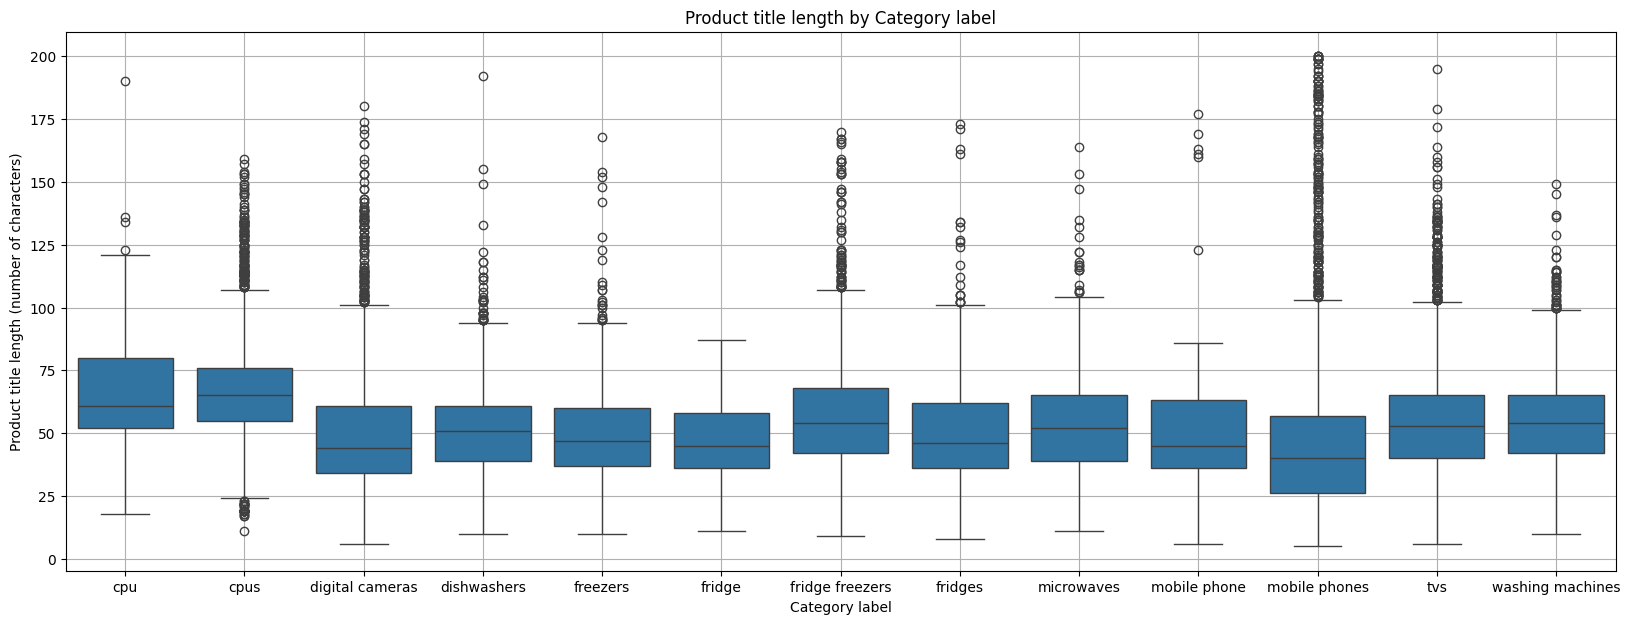

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create new column with length of each product_title
df['product_title_length'] = df['product_title'].astype(str).str.len()

# Show basic stats
print("Product title length summary:")
print(df['product_title_length'].describe())
print()
# Group by category and describe product title length
print("Product title length statistics by category label:")
print()
print(df.groupby('category_label', observed=False)['product_title_length'].describe())


# Visualize distribution of product title length by category
plt.figure(figsize=(20, 7))
sns.boxplot(data=df, x='category_label', y='product_title_length')
plt.title("Product title length by Category label")
plt.xlabel("Category label")
plt.ylabel("Product title length (number of characters)")
plt.grid(True)
plt.show()

## Some advanced features engineering

In [34]:
import pandas as pd
import re

# Number of words and characters with and without space from the title
df["title_word_count"] = df["product_title"].apply( lambda title: len(title.split()) )

df["title_char_count"] = df["product_title"].str.replace( r"\s", "", regex=True ).str.len()

df["title_char_count_spaces"] = df["product_title"].str.len()

# check if are numbers
df["title_has_numbers"] = df["product_title"].str.contains( r"\d", regex=True )

# check special characters
df["title_has_special_chars"] = df["product_title"].str.contains( r"[^a-zA-Z0-9\s]", regex=True )


# check the upperscore title
def is_uppercase(title):
  letters = re.sub(r"[^a-zA-Z]", "", title)
  return bool(letters) and letters.isupper()

df["title_is_uppercase"] = df["product_title"].apply(is_uppercase)


# the longest word
def longest_word(title):
  words = re.findall(r"\b\w+\b", title)
  if not words:
    return ""
  return max(words, key=len)

df["title_longest_word"] = df["product_title"].apply(longest_word)

df["title_longest_word_length"] = df["title_longest_word"].str.len()

# display some results:
columns_to_display = [ "product_title", "title_word_count", "title_char_count",
                      "title_char_count_spaces", "title_has_numbers",
                       "title_has_special_chars", "title_is_uppercase",
                       "title_longest_word", "title_longest_word_length" ]

df[columns_to_display].head(10)

,product_title,title_word_count,title_char_count,title_char_count_spaces,title_has_numbers,title_has_special_chars,title_is_uppercase,title_longest_word,title_longest_word_length
0,apple iphone 8 plus 64gb silver,6,26,31,True,False,False,iphone,6
1,apple iphone 8 plus 64 gb spacegrau,7,29,35,True,False,False,spacegrau,9
2,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...,13,58,70,True,True,False,smartphone,10
3,apple iphone 8 plus 64gb space grey,7,29,35,True,False,False,iphone,6
4,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,11,44,54,True,True,False,unlocked,8
5,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,11,44,54,True,True,False,unlocked,8
6,apple iphone 8 plus 64 gb space grey,8,29,36,True,False,False,iphone,6
7,apple iphone 8 plus 64gb space grey,7,29,35,True,False,False,iphone,6
8,apple iphone 8 plus 64gb space grey,7,29,35,True,False,False,iphone,6
9,apple iphone 8 plus 64gb space grey,7,29,35,True,False,False,iphone,6


## Extract the brand name

In [31]:
# Extract the first word from product_title
df["product_brand"] = (
    df["product_title"]
    .fillna("")
    .str.strip()
    .str.split()
    .str[0]
    .str.lower()
)

# Display the results
print(df[["product_title", "product_brand"]])

                                           product_title product_brand
0                        apple iphone 8 plus 64gb silver         apple
1                    apple iphone 8 plus 64 gb spacegrau         apple
2      apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...         apple
3                    apple iphone 8 plus 64gb space grey         apple
4      apple iphone 8 plus gold 5.5 64gb 4g unlocked ...         apple
...                                                  ...           ...
35306  smeg fab28 60cm retro style right hand hinge f...          smeg
35307  smeg fab28 60cm retro style left hand hinge fr...          smeg
35308  smeg fab28 60cm retro style left hand hinge fr...          smeg
35309     candy 60cm built under larder fridge cru160nek         candy
35310           neff k4316x7gb built under larder fridge          neff

[34760 rows x 2 columns]
